In [ ]:
#Hansı yaş qrupunda daha çox müştəri var?

#Hansı yaş qrupu daha çox pul xərcləyir?

#Təhsil səviyyəsi ilə alış davranışı arasında fərq varmı?

#Evli və subay müştərilərin xərcləmə davranışları necə fərqlənir?

#Hansı gəlir qrupunda alış sayı daha yüksəkdir?

#Hansı ölkədə daha çox müştəri və xərcləmə var?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)

file_path = Path(
    "../05_Clean_Data/marketing_data_clean.csv"
)

df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (2240, 46)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country,Income_Was_Missing,Income_Imputed,Education_Standardized,Marital_Status_Group,Country_Standardized,Income_Is_Outlier,Total_Spending,Total_Purchases,Total_Children,Total_Accepted_Campaigns,Customer_Age_Estimated,Age_Group,Income_Group,Enrollment_Year,Enrollment_Month,Enrollment_Quarter,Enrollment_Month_Name,Customer_Tenure_Days
0,1826,1970,Graduation,Divorced,84835.0,0,0,2014-06-16,0,189,104,379,111,189,218,1,4,4,6,1,0,0,0,0,0,1,0,Spain,0,84835.0,Graduate,Divorced,Spain,0,1190,14,0,1,44,35-44,High Income,2014,6,2,June,14
1,1,1961,Graduation,Single,57091.0,0,0,2014-06-15,0,464,5,64,7,0,37,1,7,3,7,5,0,0,0,0,1,1,0,Canada,0,57091.0,Graduate,Single,Canada,0,577,17,0,2,53,45-54,Upper-Middle Income,2014,6,2,June,15
2,10476,1958,Graduation,Married,67267.0,0,1,2014-05-13,0,134,11,59,15,2,30,1,3,2,5,2,0,0,0,0,0,0,0,USA,0,67267.0,Graduate,Married,Usa,0,251,10,1,0,56,55-64,Upper-Middle Income,2014,5,2,May,48
3,1386,1967,Graduation,Together,32474.0,1,1,2014-05-11,0,10,0,1,0,0,0,1,1,0,2,7,0,0,0,0,0,0,0,Australia,0,32474.0,Graduate,Partnered,Australia,0,11,3,2,0,47,45-54,Low Income,2014,5,2,May,50
4,5371,1989,Graduation,Single,21474.0,1,0,2014-04-08,0,6,16,24,11,0,34,2,3,1,2,7,1,0,0,0,0,1,0,Spain,0,21474.0,Graduate,Single,Spain,0,91,6,1,2,25,25-34,Low Income,2014,4,2,April,83


In [2]:
required_columns = [
    "ID",
    "Age_Group",
    "Education_Standardized",
    "Marital_Status_Group",
    "Income_Group",
    "Country_Standardized",
    "Total_Spending",
    "Total_Purchases"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

print("Missing Columns:", missing_columns)

Missing Columns: []


In [3]:
age_distribution = (
    df.groupby("Age_Group", dropna=False)
    .agg(
        Total_Customers=("ID", "nunique")
    )
    .reset_index()
)

age_distribution["Customer_Percentage"] = (
    age_distribution["Total_Customers"]
    / df["ID"].nunique()
    * 100
).round(2)

display(age_distribution)

,Age_Group,Total_Customers,Customer_Percentage
0,18-24,61,2.72
1,25-34,363,16.21
2,35-44,740,33.04
3,45-54,506,22.59
4,55-64,460,20.54
5,65+,107,4.78
6,NaN,3,0.13


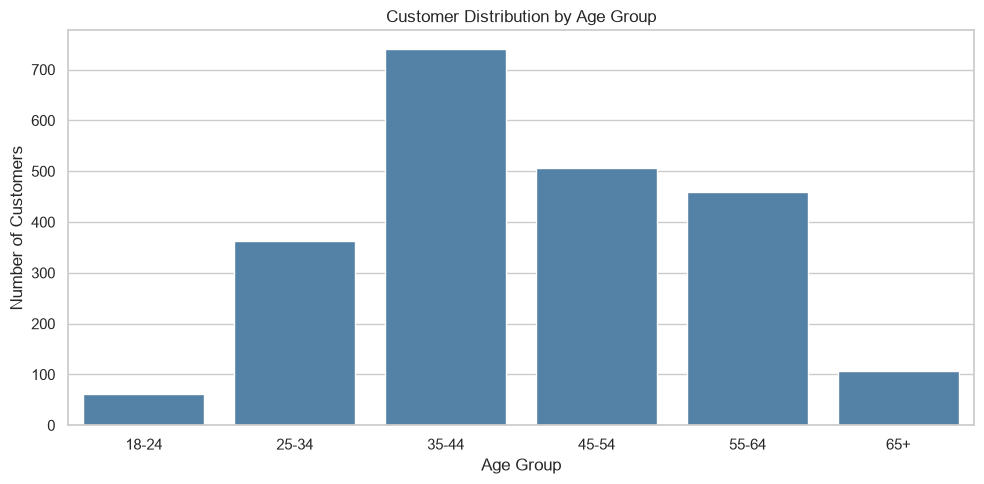

In [4]:
age_order = [
    "18-24",
    "25-34",
    "35-44",
    "45-54",
    "55-64",
    "65+"
]

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Age_Group",
    order=age_order,
    color="steelblue"
)

plt.title("Customer Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [5]:
age_spending = (
    df.groupby("Age_Group", observed=True)
    .agg(
        Total_Customers=("ID", "nunique"),
        Total_Spending=("Total_Spending", "sum"),
        Avg_Spending=("Total_Spending", "mean"),
        Avg_Purchases=("Total_Purchases", "mean")
    )
    .reset_index()
)

display(age_spending.round(2))

,Age_Group,Total_Customers,Total_Spending,Avg_Spending,Avg_Purchases
0,18-24,61,49445,810.57,12.95
1,25-34,363,193207,532.25,10.85
2,35-44,740,387185,523.22,11.55
3,45-54,506,315446,623.41,13.18
4,55-64,460,309865,673.62,13.82
5,65+,107,99900,933.64,16.48


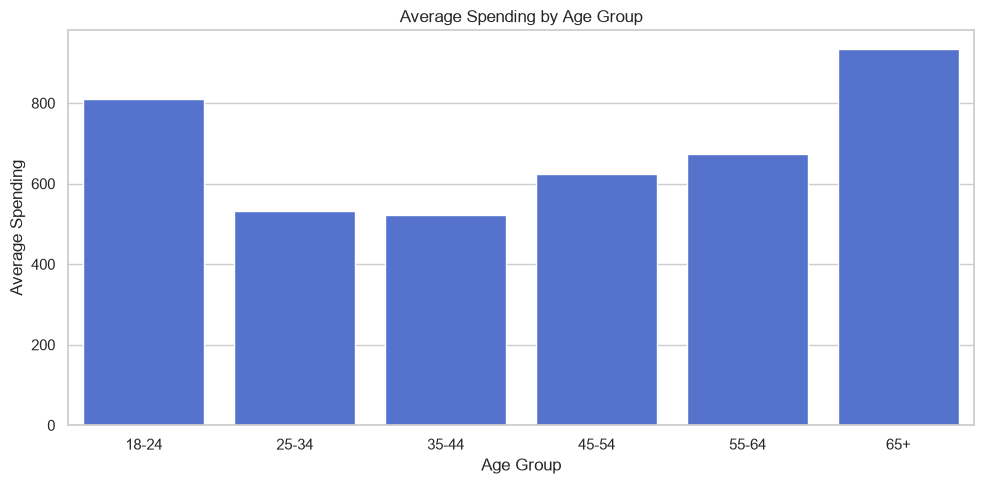

In [6]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=age_spending,
    x="Age_Group",
    y="Avg_Spending",
    color="royalblue"
)

plt.title("Average Spending by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Spending")

plt.tight_layout()
plt.show()

In [7]:
education_analysis = (
    df.groupby("Education_Standardized", dropna=False)
    .agg(
        Total_Customers=("ID", "nunique"),
        Total_Spending=("Total_Spending", "sum"),
        Avg_Spending=("Total_Spending", "mean"),
        Avg_Purchases=("Total_Purchases", "mean")
    )
    .reset_index()
)

education_analysis = education_analysis.sort_values(
    "Avg_Spending",
    ascending=False
)

display(education_analysis.round(2))

,Education_Standardized,Total_Customers,Total_Spending,Avg_Spending,Avg_Purchases
1,Doctorate,486,326791,672.41,13.45
2,Graduate,1127,698626,619.90,12.68
3,Master's Degree,370,226359,611.78,12.50
4,Second Cycle,203,100795,496.53,11.56
0,Basic Education,54,4417,81.80,5.22


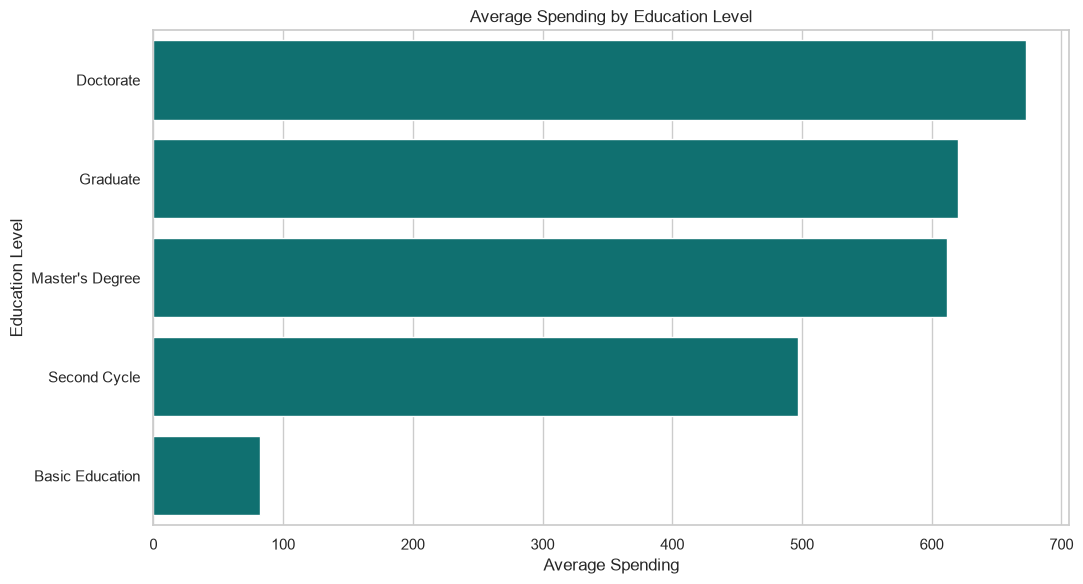

In [8]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=education_analysis,
    y="Education_Standardized",
    x="Avg_Spending",
    color="teal"
)

plt.title("Average Spending by Education Level")
plt.xlabel("Average Spending")
plt.ylabel("Education Level")

plt.tight_layout()
plt.show()

In [9]:
marital_analysis = (
    df.groupby("Marital_Status_Group", dropna=False)
    .agg(
        Total_Customers=("ID", "nunique"),
        Total_Spending=("Total_Spending", "sum"),
        Avg_Spending=("Total_Spending", "mean"),
        Avg_Purchases=("Total_Purchases", "mean")
    )
    .reset_index()
)

display(
    marital_analysis.sort_values(
        "Avg_Spending",
        ascending=False
    ).round(2)
)

,Marital_Status_Group,Total_Customers,Total_Spending,Avg_Spending,Avg_Purchases
5,Unknown,4,3233,808.25,15.75
6,Widowed,77,56889,738.82,14.36
0,Divorced,232,141666,610.63,12.80
3,Partnered,580,352865,608.39,12.49
4,Single,480,291112,606.48,12.11
2,Married,864,510453,590.80,12.56
1,Living Alone,3,770,256.67,9.67


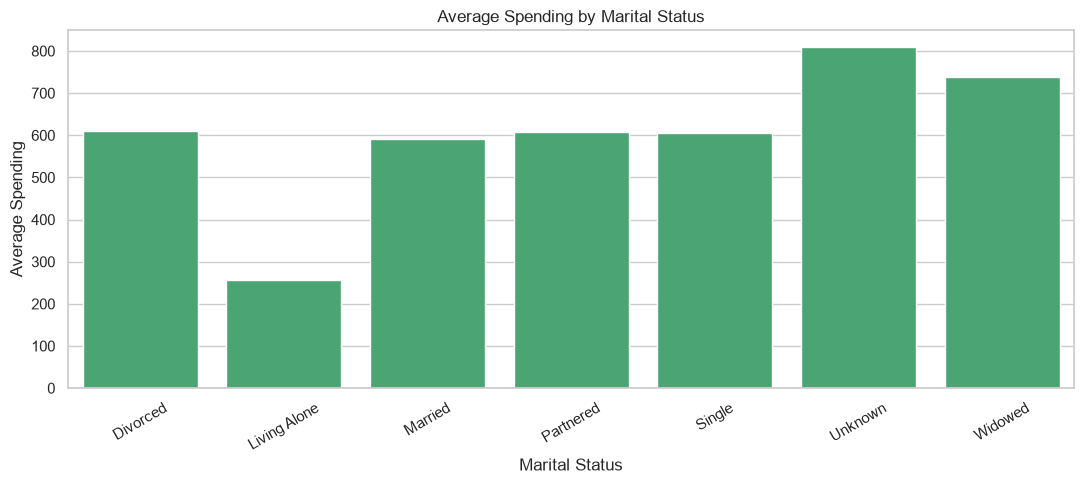

In [10]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=marital_analysis,
    x="Marital_Status_Group",
    y="Avg_Spending",
    color="mediumseagreen"
)

plt.title("Average Spending by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Average Spending")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [11]:
income_analysis = (
    df.groupby("Income_Group", dropna=False)
    .agg(
        Total_Customers=("ID", "nunique"),
        Avg_Income=("Income", "mean"),
        Total_Spending=("Total_Spending", "sum"),
        Avg_Spending=("Total_Spending", "mean"),
        Avg_Purchases=("Total_Purchases", "mean")
    )
    .reset_index()
)

display(income_analysis.round(2))

,Income_Group,Total_Customers,Avg_Income,Total_Spending,Avg_Spending,Avg_Purchases
0,High Income,554,80580.90,752139,1357.65,19.32
1,Low Income,554,25187.11,45202,81.59,5.45
2,Lower-Middle Income,554,43060.12,128149,231.32,8.77
3,Upper-Middle Income,554,60160.88,419789,757.74,16.68
4,NaN,24,NaN,11709,487.88,10.67


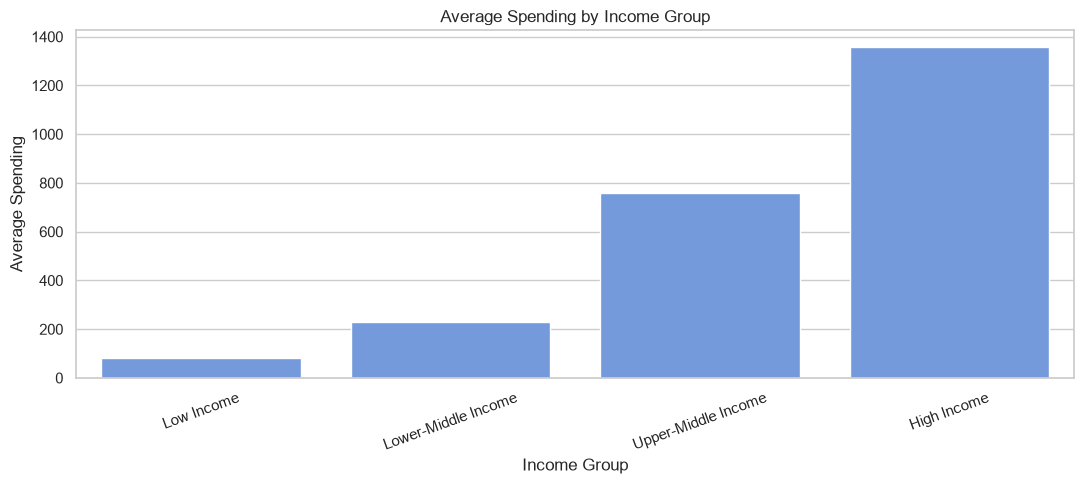

In [12]:
income_order = [
    "Low Income",
    "Lower-Middle Income",
    "Upper-Middle Income",
    "High Income"
]

plt.figure(figsize=(11, 5))

sns.barplot(
    data=df,
    x="Income_Group",
    y="Total_Spending",
    order=income_order,
    estimator="mean",
    errorbar=None,
    color="cornflowerblue"
)

plt.title("Average Spending by Income Group")
plt.xlabel("Income Group")
plt.ylabel("Average Spending")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [13]:
country_analysis = (
    df.groupby("Country_Standardized", dropna=False)
    .agg(
        Total_Customers=("ID", "nunique"),
        Total_Spending=("Total_Spending", "sum"),
        Avg_Spending=("Total_Spending", "mean"),
        Avg_Purchases=("Total_Purchases", "mean")
    )
    .reset_index()
)

country_analysis = country_analysis.sort_values(
    "Total_Spending",
    ascending=False
)

display(country_analysis.round(2))

,Country_Standardized,Total_Customers,Total_Spending,Avg_Spending,Avg_Purchases
6,Spain,1095,662220,604.77,12.40
5,Saudi Arabia,337,211071,626.32,12.77
1,Canada,268,168532,628.85,12.90
0,Australia,160,89763,561.02,12.20
3,India,148,79485,537.06,11.72
2,Germany,120,74913,624.28,12.75
7,Usa,109,67882,622.77,13.51
4,Mexico,3,3122,1040.67,17.33


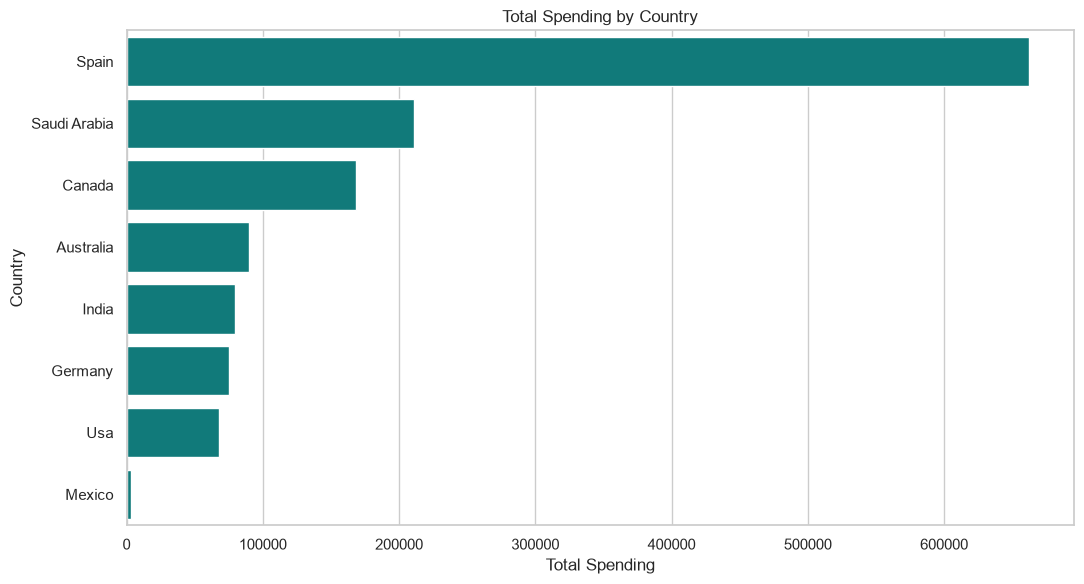

In [14]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=country_analysis,
    y="Country_Standardized",
    x="Total_Spending",
    color="darkcyan"
)

plt.title("Total Spending by Country")
plt.xlabel("Total Spending")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

In [16]:
household_analysis = (
    df.groupby("Total_Children", dropna=False)
    .agg(
        Total_Customers=("ID", "nunique"),
        Avg_Spending=("Total_Spending", "mean"),
        Avg_Purchases=("Total_Purchases", "mean")
    )
    .reset_index()
)

display(household_analysis.round(2))

,Total_Children,Total_Customers,Avg_Spending,Avg_Purchases
0,0,638,1106.03,16.42
1,1,1128,472.73,12.01
2,2,421,245.95,8.65
3,3,53,274.60,7.89


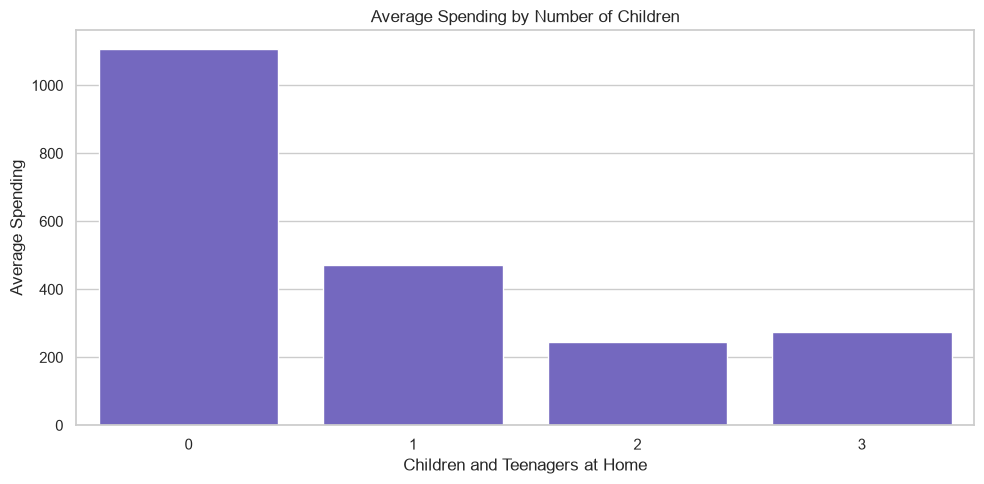

In [17]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=household_analysis,
    x="Total_Children",
    y="Avg_Spending",
    color="slateblue"
)

plt.title("Average Spending by Number of Children")
plt.xlabel("Children and Teenagers at Home")
plt.ylabel("Average Spending")

plt.tight_layout()
plt.show()

In [18]:
segment_analysis = (
    df.groupby(
        ["Age_Group", "Income_Group"],
        observed=True
    )
    .agg(
        Total_Customers=("ID", "nunique"),
        Avg_Spending=("Total_Spending", "mean")
    )
    .reset_index()
)

display(segment_analysis.round(2))

,Age_Group,Income_Group,Total_Customers,Avg_Spending
0,18-24,High Income,26,1454.08
1,18-24,Low Income,24,87.54
2,18-24,Lower-Middle Income,7,449.86
3,18-24,Upper-Middle Income,4,1597.25
4,25-34,High Income,88,1424.02
5,25-34,Low Income,151,76.29
6,25-34,Lower-Middle Income,80,218.18
7,25-34,Upper-Middle Income,39,937.41
8,35-44,High Income,150,1361.28
9,35-44,Low Income,222,78.12


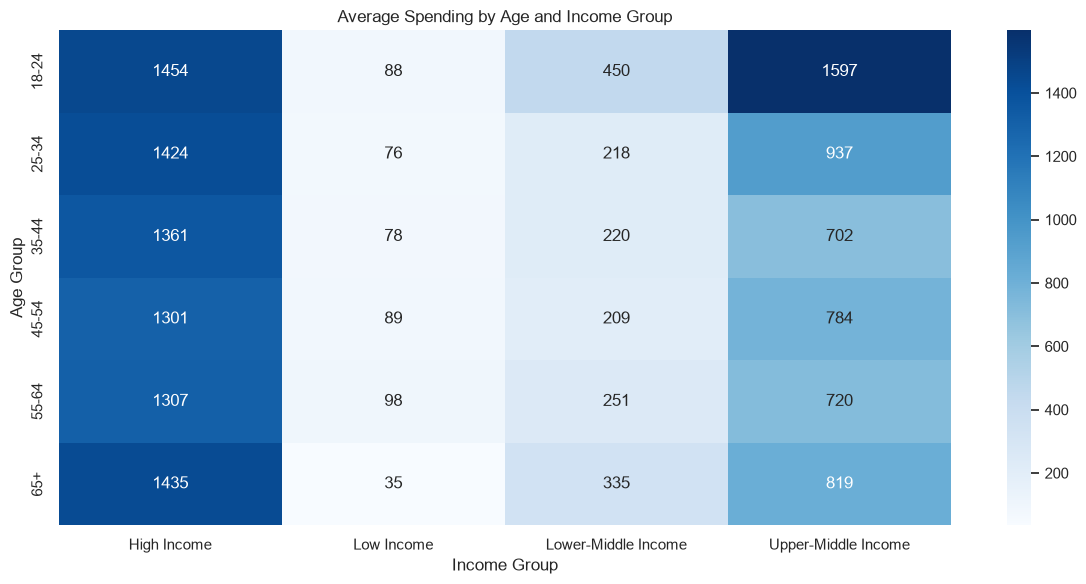

In [19]:
heatmap_data = segment_analysis.pivot(
    index="Age_Group",
    columns="Income_Group",
    values="Avg_Spending"
)

plt.figure(figsize=(12, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="Blues"
)

plt.title("Average Spending by Age and Income Group")
plt.xlabel("Income Group")
plt.ylabel("Age Group")

plt.tight_layout()
plt.show()

In [20]:
demographic_summary = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Average Estimated Age",
        "Average Income",
        "Average Spending",
        "Average Purchases",
        "Total Spending"
    ],
    "Value": [
        df["ID"].nunique(),
        df.loc[
            df["Customer_Age_Estimated"].between(18, 100),
            "Customer_Age_Estimated"
        ].mean(),
        df["Income"].mean(),
        df["Total_Spending"].mean(),
        df["Total_Purchases"].mean(),
        df["Total_Spending"].sum()
    ]
})

display(demographic_summary.round(2))

,Metric,Value
0,Total Customers,2240.00
1,Average Estimated Age,45.10
2,Average Income,52247.25
3,Average Spending,605.80
4,Average Purchases,12.54
5,Total Spending,1356988.00
